## 1. Environment and imports

In [2]:


import os, re, html, time, copy, random, json
from collections import Counter
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score
)
from tqdm.auto import tqdm

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("results/checkpoints", exist_ok=True)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Reproducibility where practical (may reduce speed).
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

Device: cuda
GPU: Tesla T4


In [3]:
import pandas as pd

TRAIN_PATH = "/content/drugsComTrain_raw.tsv"
TEST_PATH = "/content/drugsComTest_raw.tsv"

train_raw = pd.read_csv(TRAIN_PATH, sep="\t")
test_raw = pd.read_csv(TEST_PATH, sep="\t")

print("Training reviews:", len(train_raw))
print("Testing reviews:", len(test_raw))

Training reviews: 161297
Testing reviews: 53766


## 2. Load the official files

In [4]:
import os
import pandas as pd

DATA_DIR = "/content"

TRAIN_FILE = os.path.join(DATA_DIR, "drugsComTrain_raw.tsv")
TEST_FILE = os.path.join(DATA_DIR, "drugsComTest_raw.tsv")

# Verify both files exist
assert os.path.isfile(TRAIN_FILE), "Training file not found!"
assert os.path.isfile(TEST_FILE), "Test file not found!"

print("Dataset directory:", DATA_DIR)
print("Training file:", TRAIN_FILE)
print("Test file:", TEST_FILE)

Dataset directory: /content
Training file: /content/drugsComTrain_raw.tsv
Test file: /content/drugsComTest_raw.tsv


In [5]:
train_raw = pd.read_csv(TRAIN_FILE, sep="\t")
test_raw = pd.read_csv(TEST_FILE, sep="\t")
print("Raw train:", train_raw.shape, "| Raw test:", test_raw.shape)
display(train_raw.head())

Raw train: (161297, 7) | Raw test: (53766, 7)


,Unnamed: 0,drugName,condition,review,rating,date,usefulCount
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combinati...",9.0,"May 20, 2012",27
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of ...",8.0,"April 27, 2010",192
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, wh...",5.0,"December 14, 2009",17
3,138000,Ortho Evra,Birth Control,"""This is my first time using any form of birth...",8.0,"November 3, 2015",10
4,35696,Buprenorphine / naloxone,Opiate Dependence,"""Suboxone has completely turned my life around...",9.0,"November 27, 2016",37


In [6]:

# 1. Vérifier les colonnes et les dimensions
print("Train :", train_raw.shape)
print("Test :", test_raw.shape)

print("\nColonnes du train :")
print(train_raw.columns.tolist())

# 2. Afficher quelques avis et leurs notes
display(train_raw[["review", "rating"]].head(5))

# 3. Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(train_raw[["review", "rating"]].isna().sum())

# 4. Vérifier les notes
print("\nRépartition des notes :")
print(train_raw["rating"].value_counts().sort_index())


Train : (161297, 7)
Test : (53766, 7)

Colonnes du train :
['Unnamed: 0', 'drugName', 'condition', 'review', 'rating', 'date', 'usefulCount']


,review,rating
0,"""It has no side effect, I take it in combinati...",9.0
1,"""My son is halfway through his fourth week of ...",8.0
2,"""I used to take another oral contraceptive, wh...",5.0
3,"""This is my first time using any form of birth...",8.0
4,"""Suboxone has completely turned my life around...",9.0



Valeurs manquantes :
review    0
rating    0
dtype: int64

Répartition des notes :
rating
1.0     21619
2.0      6931
3.0      6513
4.0      5012
5.0      8013
6.0      6343
7.0      9456
8.0     18890
9.0     27531
10.0    50989
Name: count, dtype: int64


## 3. Clean and label the reviews

In [7]:
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
NUM_CLASSES = 3

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\\s+", " ", text)
    return text.strip()

def prepare_dataframe(df):
    required = {"review", "rating"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    out = df[["review", "rating"]].copy()
    out = out.dropna(subset=["review", "rating"])
    out["review"] = out["review"].map(clean_text)
    out["rating"] = pd.to_numeric(out["rating"], errors="coerce")
    out = out.dropna(subset=["rating"])
    out = out[out["rating"].between(1, 10)]
    out = out[out["review"].str.len() > 0]
    out["label"] = np.select(
        [out["rating"].between(1, 4),
         out["rating"].between(5, 6),
         out["rating"].between(7, 10)],
        [0, 1, 2], default=-1
    ).astype(int)
    return out.reset_index(drop=True)

train_df = prepare_dataframe(train_raw)
test_df = prepare_dataframe(test_raw)


print("Exact duplicate rows in train:", train_df.duplicated().sum())
print("Exact duplicate review texts in train:", train_df["review"].duplicated().sum())
print("Exact duplicate rows in official test:", test_df.duplicated().sum())
print("Exact duplicate review texts in official test:", test_df["review"].duplicated().sum())


REMOVE_EXACT_DUPLICATE_ROWS_WITHIN_SPLIT = False
if REMOVE_EXACT_DUPLICATE_ROWS_WITHIN_SPLIT:
    train_df = train_df.drop_duplicates(subset=["review", "rating"]).reset_index(drop=True)
    test_df = test_df.drop_duplicates(subset=["review", "rating"]).reset_index(drop=True)

print("Prepared train:", train_df.shape, "| Prepared test:", test_df.shape)
display(train_df.head())

Exact duplicate rows in train: 48879
Exact duplicate review texts in train: 48968
Exact duplicate rows in official test: 5464
Exact duplicate review texts in official test: 5486
Prepared train: (161297, 3) | Prepared test: (53766, 3)


,review,rating,label
0,"""It has no side effect, I take it in combinati...",9.0,2
1,"""My son is halfway through his fourth week of ...",8.0,2
2,"""I used to take another oral contraceptive, wh...",5.0,1
3,"""This is my first time using any form of birth...",8.0,2
4,"""Suboxone has completely turned my life around...",9.0,2


## 5. Split train into train/validation; keep official test untouched

In [8]:
import re
from sklearn.model_selection import train_test_split

# ============================================
# 1. Create normalized review identifiers
# ============================================

def review_key(text):
    tokens = re.findall(
        r"\b\w+\b|[^\w\s]",
        str(text).lower()
    )
    return " ".join(tokens)

train_pool = train_df.copy()
test_full = test_df.copy()

train_pool["_review_key"] = train_pool["review"].map(review_key)
test_full["_review_key"] = test_full["review"].map(review_key)

# ============================================
# 2. Remove overlap with the official test set
# ============================================

test_keys = set(test_full["_review_key"])

train_pool = train_pool[
    ~train_pool["_review_key"].isin(test_keys)
].copy()

# Remove duplicated review texts
train_pool = train_pool.drop_duplicates(
    subset=["_review_key"]
).reset_index(drop=True)

# ============================================
# 3. Split into training and validation
# ============================================

train_df, val_df = train_test_split(
    train_pool,
    test_size=0.15,
    random_state=SEED,
    stratify=train_pool["label"]
)

# ============================================
# 4. Keep 60% to maintain similar dataset sizes
# ============================================

train_small, _ = train_test_split(
    train_df,
    train_size=0.60,
    random_state=SEED,
    stratify=train_df["label"]
)

val_small, _ = train_test_split(
    val_df,
    train_size=0.60,
    random_state=SEED,
    stratify=val_df["label"]
)

train_small = train_small.reset_index(drop=True)
val_small = val_small.reset_index(drop=True)
test_full = test_full.reset_index(drop=True)

# ============================================
# 5. Verify there is no overlap
# ============================================

train_keys = set(train_small["_review_key"])
val_keys = set(val_small["_review_key"])
test_keys = set(test_full["_review_key"])

print("Train / Validation overlap:", len(train_keys & val_keys))
print("Train / Test overlap:", len(train_keys & test_keys))
print("Validation / Test overlap:", len(val_keys & test_keys))

# ============================================
# 6. Display dataset sizes and class proportions
# ============================================

for split_name, split_df in [
    ("Reduced Train (60%)", train_small),
    ("Reduced Validation (60%)", val_small),
    ("Full Official Test", test_full)
]:
    print(f"\n{split_name}: {len(split_df):,} samples")
    print(
        split_df["label"]
        .value_counts(normalize=True)
        .sort_index()
        .round(3)
        .rename(index=dict(enumerate(LABEL_NAMES)))
    )

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0

Reduced Train (60%): 40,882 samples
label
Negative    0.246
Neutral     0.089
Positive    0.665
Name: proportion, dtype: float64

Reduced Validation (60%): 7,215 samples
label
Negative    0.246
Neutral     0.089
Positive    0.665
Name: proportion, dtype: float64

Full Official Test: 53,766 samples
label
Negative    0.251
Neutral     0.090
Positive    0.659
Name: proportion, dtype: float64


## 4. Exploratory data analysis

Reduced train class counts:


,count
label,
Negative,10060
Neutral,3619
Positive,27203


Reduced train class proportions:


,proportion
label,
Negative,0.246
Neutral,0.089
Positive,0.665


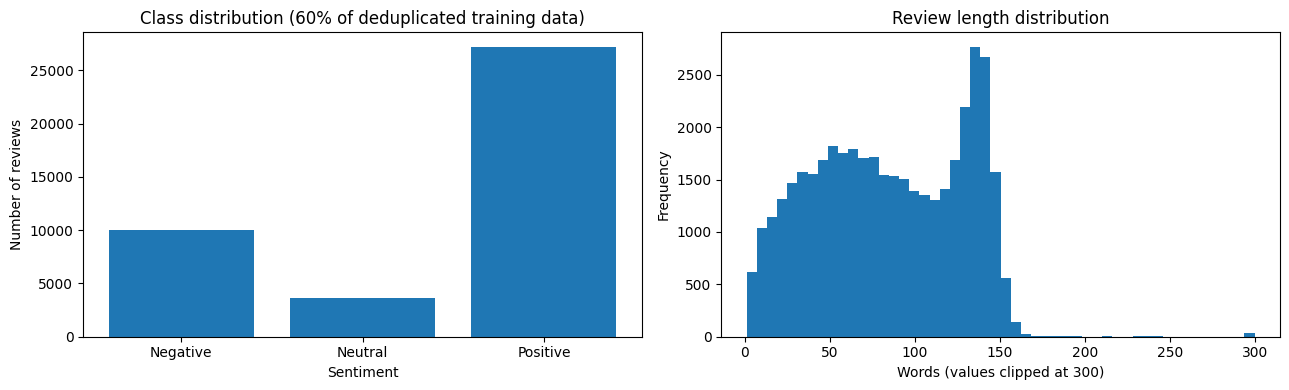

In [28]:



counts = train_small["label"].value_counts().sort_index()

print("Reduced train class counts:")
display(counts.rename(index=dict(enumerate(LABEL_NAMES))))

print("Reduced train class proportions:")
display(
    train_small["label"]
    .value_counts(normalize=True)
    .sort_index()
    .round(3)
    .rename(index=dict(enumerate(LABEL_NAMES)))
)

# Review length
train_small["word_count"] = (
    train_small["review"].str.split().str.len()
)

# Plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(LABEL_NAMES, counts.values)
axes[0].set(
    title="Class distribution (60% of deduplicated training data)",
    xlabel="Sentiment",
    ylabel="Number of reviews"
)

axes[1].hist(
    train_small["word_count"].clip(upper=300),
    bins=50
)
axes[1].set(
    title="Review length distribution",
    xlabel="Words (values clipped at 300)",
    ylabel="Frequency"
)

plt.tight_layout()
plt.savefig("results/eda.png", dpi=200)
plt.show()


## 6. Tokenization and vocabulary
The vocabulary is built from **training text only** to avoid information leakage.

In [10]:

PAD_IDX, UNK_IDX = 0, 1
MAX_VOCAB_SIZE = 30000
MAX_LEN = 100
EMBED_DIM = 128

def tokenize(text):
    return re.findall(r"\b\w+\b|[^\w\s]", text.lower())

# Building  the vocabulary using only the reduced training set
counter = Counter()
for text in tqdm(train_small["review"], desc="Building train vocabulary"):
    counter.update(tokenize(text))

vocab = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}

for token, _ in counter.most_common(MAX_VOCAB_SIZE - 2):
    if token not in vocab:
        vocab[token] = len(vocab)

print("Vocabulary size:", len(vocab))


Building train vocabulary:   0%|          | 0/40882 [00:00<?, ?it/s]

Vocabulary size: 30000


In [11]:
# Save the exact token-to-index mapping .
import json, os
os.makedirs("results", exist_ok=True)
with open("results/vocab.json", "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False)
print("Saved results/vocab.json")

Saved results/vocab.json


## 7. Dataset and batch loading

In [12]:

class DrugReviewDataset(Dataset):
    def __init__(self, dataframe, vocab, max_len=MAX_LEN):
        self.texts = dataframe["review"].tolist()
        self.labels = dataframe["label"].astype(int).tolist()
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        tokens = tokenize(self.texts[idx])[:self.max_len]
        ids = [self.vocab.get(token, UNK_IDX) for token in tokens]

        if not ids:
            ids = [UNK_IDX]

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )


def collate_batch(batch):
    sequences, labels = zip(*batch)

    lengths = torch.tensor(
        [len(seq) for seq in sequences],
        dtype=torch.long
    )

    padded = torch.full(
        (len(batch), int(lengths.max())),
        PAD_IDX,
        dtype=torch.long
    )

    for i, seq in enumerate(sequences):
        padded[i, :len(seq)] = seq

    return padded, lengths, torch.stack(labels)



train_dataset = DrugReviewDataset(train_small, vocab)
val_dataset = DrugReviewDataset(val_small, vocab)

# Keeping  the complete  test set
test_dataset = DrugReviewDataset(test_full, vocab)


def make_loader(dataset, batch_size, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_batch,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
        generator=generator
    )


print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))


Train dataset: 40882
Validation dataset: 7215
Test dataset: 53766


## 8. Custom recurrent cells (using `nn.Linear` only)
The LSTMP cell follows the appendix: the internal cell state has dimension H; the recurrent hidden output has projection dimension P.

In [13]:
class VanillaLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.x_gates = nn.Linear(input_dim, 4 * hidden_dim)
        self.h_gates = nn.Linear(hidden_dim, 4 * hidden_dim)

    def forward(self, x, h, c):
        i, f, o, g = (self.x_gates(x) + self.h_gates(h)).chunk(4, dim=-1)
        i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        c_new = f * c + i * g
        h_new = o * torch.tanh(c_new)
        return h_new, c_new


class CIFGLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.x_gates = nn.Linear(input_dim, 3 * hidden_dim)
        self.h_gates = nn.Linear(hidden_dim, 3 * hidden_dim)

    def forward(self, x, h, c):
        f, o, g = (self.x_gates(x) + self.h_gates(h)).chunk(3, dim=-1)
        f = torch.sigmoid(f)
        i = 1.0 - f
        o, g = torch.sigmoid(o), torch.tanh(g)
        c_new = f * c + i * g
        h_new = o * torch.tanh(c_new)
        return h_new, c_new


class LSTMPCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, proj_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.proj_dim = proj_dim
        self.x_gates = nn.Linear(input_dim, 4 * hidden_dim)
        self.h_gates = nn.Linear(proj_dim, 4 * hidden_dim)
        self.projection = nn.Linear(hidden_dim, proj_dim)

    def forward(self, x, h, c):
        i, f, o, g = (self.x_gates(x) + self.h_gates(h)).chunk(4, dim=-1)
        i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        c_new = f * c + i * g
        m = o * torch.tanh(c_new)
        h_new = self.projection(m)
        return h_new, c_new

## 9. Classifier and initialization options

In [14]:

class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=EMBED_DIM,
        hidden_dim=128,
        num_classes=NUM_CLASSES,
        cell_type="vanilla",
        proj_dim=96,
        dropout=0.3,
        init_type="default"
    ):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.cell_type = cell_type
        self.proj_dim = proj_dim if cell_type == "lstmp" else hidden_dim

        # Embedding layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        # Selecting the recurrent cell
        if cell_type == "vanilla":
            self.cell = VanillaLSTMCell(embed_dim, hidden_dim)

        elif cell_type == "cifg":
            self.cell = CIFGLSTMCell(embed_dim, hidden_dim)

        elif cell_type == "lstmp":
            self.cell = LSTMPCell(embed_dim, hidden_dim, proj_dim)

        else:
            raise ValueError(f"Unknown cell_type: {cell_type}")

        # Dropout and classification layer
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.proj_dim, num_classes)

        # Initialize model weights
        self.initialize_weights(init_type)

    def initialize_weights(self, init_type):
        if init_type != "default":
            for name, param in self.named_parameters():

                if param.dim() >= 2:
                    if init_type == "xavier_uniform":
                        nn.init.xavier_uniform_(param)

                    elif init_type == "xavier_normal":
                        nn.init.xavier_normal_(param)

                    else:
                        raise ValueError(
                            f"Unknown init_type: {init_type}"
                        )

                elif "bias" in name:
                    nn.init.zeros_(param)

        #  keeping padding embedding row at zero
        with torch.no_grad():
            self.embedding.weight[PAD_IDX].zero_()

    def forward(self, input_ids, lengths):
        # Convert token IDs into embeddings
        embedded = self.embedding(input_ids)

        batch_size, seq_len, _ = embedded.shape

        # Initialize hidden state and cell state
        h = embedded.new_zeros(batch_size, self.proj_dim)
        c = embedded.new_zeros(batch_size, self.hidden_dim)

        # Processing  the sequence one token at a time
        for t in range(seq_len):
            h_new, c_new = self.cell(
                embedded[:, t, :],
                h,
                c
            )


            mask = (t < lengths).unsqueeze(1)

            h = torch.where(mask, h_new, h)
            c = torch.where(mask, c_new, c)

        # Classify using the final hidden state
        output = self.dropout(h)
        logits = self.classifier(output)

        return logits


def count_parameters(model):
    """Count the number of trainable parameters."""
    return sum(
        param.numel()
        for param in model.parameters()
        if param.requires_grad
    )


## 10. Training and evaluation functions

- Class weights are computed from the **training split only**.
- Best checkpoint is selected by validation Macro-F1.
- Test set is not used for hyperparameter selection.
- Gradient clipping and ReduceLROnPlateau are used consistently.

In [15]:

def get_class_weights(dataframe):
    counts = np.bincount(
        dataframe["label"].to_numpy(),
        minlength=NUM_CLASSES
    )

    weights = len(dataframe) / (
        NUM_CLASSES * np.maximum(counts, 1)
    )

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=DEVICE
    )


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    labels_all, preds_all = [], []

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for input_ids, lengths, labels in loader:
            input_ids = input_ids.to(DEVICE, non_blocking=True)
            lengths = lengths.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(input_ids, lengths)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )
                optimizer.step()

            total_loss += loss.item() * labels.size(0)

            preds_all.extend(
                logits.argmax(dim=1).detach().cpu().tolist()
            )
            labels_all.extend(
                labels.detach().cpu().tolist()
            )

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels_all, preds_all),
        "macro_f1": f1_score(
            labels_all,
            preds_all,
            average="macro",
            zero_division=0
        )
    }


def create_optimizer(model, name, lr, weight_decay):
    if name == "Adam":
        return torch.optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    if name == "AdamW":
        return torch.optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    if name == "SGD":
        return torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9,
            weight_decay=weight_decay
        )

    raise ValueError(f"Unsupported optimizer: {name}")


def train_model(
    model,
    train_loader,
    val_loader,
    train_dataframe,
    epochs=10,
    lr=1e-3,
    optimizer_name="Adam",
    weight_decay=0.0,
    patience=3
):
    model = model.to(DEVICE)

    # Calculating class weights from the actual training subset
    class_weights = get_class_weights(train_dataframe)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = create_optimizer(
        model,
        optimizer_name,
        lr,
        weight_decay
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )

    history = []
    best_f1 = -1.0
    best_epoch = 0
    best_state = None
    no_improvement = 0

    for epoch in range(1, epochs + 1):
        start = time.time()

        train_metrics = run_epoch(
            model, train_loader, criterion, optimizer
        )

        val_metrics = run_epoch(
            model, val_loader, criterion
        )

        scheduler.step(val_metrics["macro_f1"])

        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "lr": optimizer.param_groups[0]["lr"],
            "epoch_seconds": time.time() - start
        })

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss {train_metrics['loss']:.4f} | "
            f"val loss {val_metrics['loss']:.4f} | "
            f"val Macro-F1 {val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1

        if no_improvement >= patience:
            print(
                f"Early stopping at epoch {epoch}; "
                f"best epoch = {best_epoch}"
            )
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, pd.DataFrame(history), best_epoch


def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for input_ids, lengths, labels in loader:
            input_ids = input_ids.to(DEVICE)
            lengths = lengths.to(DEVICE)

            logits = model(input_ids, lengths)

            y_pred.extend(
                logits.argmax(dim=1).cpu().tolist()
            )
            y_true.extend(labels.tolist())

    p, r, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred)
    }


## 11. Hyperparameter experiments for **all three architectures**

For a fair, manageable comparison, each architecture receives the same candidate configurations. We vary optimizer, learning rate, and batch size. `weight_decay` is explicitly set, and initialization remains fixed at `default` in this experiment.

All candidates use the same train/validation split and Macro-F1 selection criterion.

**Controlled comparisons:** A vs C varies learning rate only; A vs D varies batch size only. **A vs B varies optimizer and weight decay together** in the existing configuration grid.

In [16]:

import os
import time
import copy
import torch
import pandas as pd

# Model architectures
MODEL_CONFIGS = {
    "Vanilla LSTM": {
        "cell_type": "vanilla",
        "hidden_dim": 128,
        "proj_dim": 96
    },
    "CIFG-LSTM": {
        "cell_type": "cifg",
        "hidden_dim": 128,
        "proj_dim": 96
    },
    "LSTMP": {
        "cell_type": "lstmp",
        "hidden_dim": 160,
        "proj_dim": 96
    },
}

# Same hyperparameter grid for each architecture
HP_CONFIGS = [
    {
        "config": "A",
        "optimizer": "Adam",
        "lr": 1e-3,
        "batch_size": 128,
        "weight_decay": 0.0
    },
    {
        "config": "B",
        "optimizer": "AdamW",
        "lr": 1e-3,
        "batch_size": 128,
        "weight_decay": 1e-4
    },
    {
        "config": "C",
        "optimizer": "Adam",
        "lr": 5e-4,
        "batch_size": 128,
        "weight_decay": 0.0
    },
    {
        "config": "D",
        "optimizer": "Adam",
        "lr": 1e-3,
        "batch_size": 64,
        "weight_decay": 0.0
    },
]

EPOCHS = 10
PATIENCE = 3
DROPOUT = 0.3

# Create output directories
os.makedirs("results/checkpoints", exist_ok=True)

# Store experiment results
experiment_rows = []
experiment_histories = {}
best_models = {}
best_settings = {}

for model_name, model_cfg in MODEL_CONFIGS.items():

    best_val_f1_for_model = -1.0

    print("\n" + "=" * 80)
    print("ARCHITECTURE:", model_name)

    for hp in HP_CONFIGS:

        run_name = f"{model_name}__{hp['config']}"
        print("\n---", run_name, "---")

        set_seed(SEED)

        # Create DataLoaders for the current batch size
        tr_loader = make_loader(
            train_dataset,
            hp["batch_size"],
            shuffle=True
        )

        va_loader = make_loader(
            val_dataset,
            hp["batch_size"],
            shuffle=False
        )

        # Creating the model
        model = LSTMClassifier(
            vocab_size=len(vocab),
            embed_dim=EMBED_DIM,
            dropout=DROPOUT,
            init_type="default",
            **model_cfg
        )

        # Train model
        start = time.time()

        model, history, best_epoch = train_model(
            model,
            tr_loader,
            va_loader,
            train_dataframe=train_small,
            epochs=EPOCHS,
            lr=hp["lr"],
            optimizer_name=hp["optimizer"],
            weight_decay=hp["weight_decay"],
            patience=PATIENCE
        )

        elapsed = time.time() - start

        # Get metrics from the best validation epoch
        best_row = history.loc[
            history["val_macro_f1"].idxmax()
        ]

        row = {
            "model": model_name,
            **hp,
            "parameters": count_parameters(model),
            "best_epoch": int(best_epoch),
            "best_val_accuracy": float(
                best_row["val_accuracy"]
            ),
            "best_val_macro_f1": float(
                best_row["val_macro_f1"]
            ),
            "training_seconds": elapsed
        }

        experiment_rows.append(row)
        experiment_histories[run_name] = history

        # Save the best configuration for this architecture
        if row["best_val_macro_f1"] > best_val_f1_for_model:

            best_val_f1_for_model = row["best_val_macro_f1"]

            best_models[model_name] = copy.deepcopy(model).to(DEVICE)
            best_settings[model_name] = hp.copy()

            filename = (
                model_name.lower()
                .replace(" ", "_")
                .replace("-", "_")
                + "_best.pt"
            )

            torch.save(
                best_models[model_name].state_dict(),
                os.path.join("results", "checkpoints", filename)
            )

            print(
                f"New best configuration for {model_name}: "
                f"{hp['config']} | "
                f"Validation Macro-F1: "
                f"{best_val_f1_for_model:.4f}"
            )

# Build the result table
hp_results_df = pd.DataFrame(experiment_rows)

display(
    hp_results_df.sort_values(
        ["model", "best_val_macro_f1"],
        ascending=[True, False]
    )
)

# Save all experiment results
hp_results_df.to_csv(
    "results/all_model_hyperparameter_experiments.csv",
    index=False
)

print("\nSelected settings by validation Macro-F1:")

display(
    pd.DataFrame([
        {"model": name, **settings}
        for name, settings in best_settings.items()
    ])
)



ARCHITECTURE: Vanilla LSTM

--- Vanilla LSTM__A ---
Epoch 01/10 | train loss 1.0572 | val loss 0.9923 | val Macro-F1 0.4644
Epoch 02/10 | train loss 0.9431 | val loss 0.9405 | val Macro-F1 0.5323
Epoch 03/10 | train loss 0.8674 | val loss 0.8978 | val Macro-F1 0.5380
Epoch 04/10 | train loss 0.7879 | val loss 0.9117 | val Macro-F1 0.5428
Epoch 05/10 | train loss 0.7191 | val loss 0.9383 | val Macro-F1 0.5309
Epoch 06/10 | train loss 0.6364 | val loss 0.9591 | val Macro-F1 0.5490
Epoch 07/10 | train loss 0.5574 | val loss 1.0329 | val Macro-F1 0.5402
Epoch 08/10 | train loss 0.4764 | val loss 1.2133 | val Macro-F1 0.5495
Epoch 09/10 | train loss 0.3945 | val loss 1.3777 | val Macro-F1 0.5472
Epoch 10/10 | train loss 0.3345 | val loss 1.4058 | val Macro-F1 0.5445
New best configuration for Vanilla LSTM: A | Validation Macro-F1: 0.5495

--- Vanilla LSTM__B ---
Epoch 01/10 | train loss 1.0590 | val loss 1.0269 | val Macro-F1 0.4681
Epoch 02/10 | train loss 0.9507 | val loss 0.9316 | val M

,model,config,optimizer,lr,batch_size,weight_decay,parameters,best_epoch,best_val_accuracy,best_val_macro_f1,training_seconds
7,CIFG-LSTM,D,Adam,0.0010,64,0.0000,3939459,5,0.689258,0.567453,570.711513
4,CIFG-LSTM,A,Adam,0.0010,128,0.0000,3939459,8,0.701317,0.564167,378.706408
5,CIFG-LSTM,B,AdamW,0.0010,128,0.0001,3939459,8,0.694664,0.562564,375.508196
6,CIFG-LSTM,C,Adam,0.0005,128,0.0000,3939459,8,0.669716,0.549046,377.859504
11,LSTMP,D,Adam,0.0010,64,0.0000,4000387,7,0.691476,0.549186,788.901136
10,LSTMP,C,Adam,0.0005,128,0.0000,4000387,7,0.672211,0.548672,416.640829
9,LSTMP,B,AdamW,0.0010,128,0.0001,4000387,4,0.660014,0.538463,292.880192
8,LSTMP,A,Adam,0.0010,128,0.0000,4000387,4,0.639917,0.535967,296.625171
2,Vanilla LSTM,C,Adam,0.0005,128,0.0000,3972483,7,0.684962,0.560413,374.321780
1,Vanilla LSTM,B,AdamW,0.0010,128,0.0001,3972483,10,0.700069,0.558388,366.855788



Selected settings by validation Macro-F1:


,model,config,optimizer,lr,batch_size,weight_decay
0,Vanilla LSTM,C,Adam,0.0005,128,0.0
1,CIFG-LSTM,D,Adam,0.0010,64,0.0
2,LSTMP,D,Adam,0.0010,64,0.0


## 12. Visualize hyperparameter comparisons

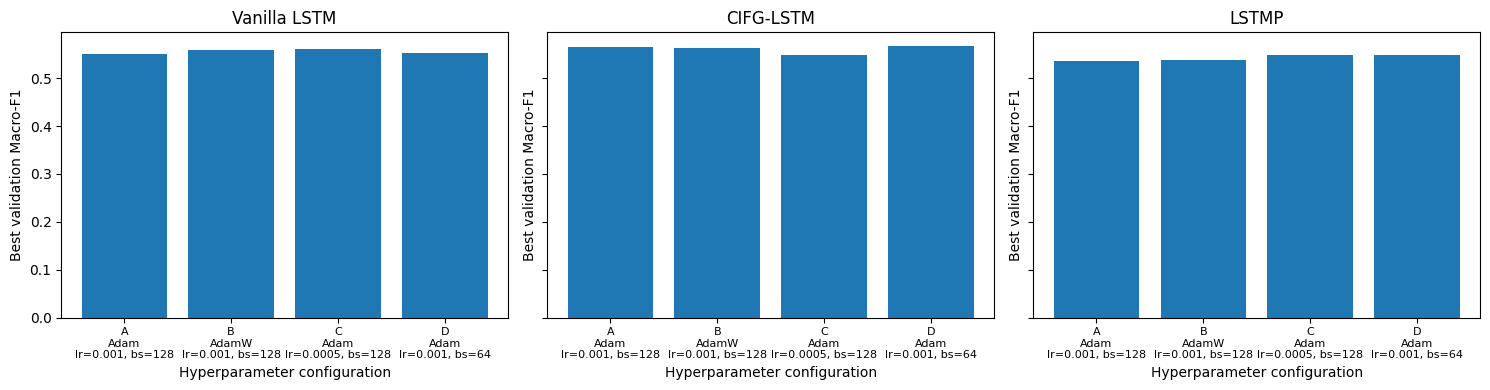

In [31]:

import os
import matplotlib.pyplot as plt

# Ensuring the output directory exists
os.makedirs("results", exist_ok=True)

# One plot per architecture -->  validation Macro-F1 for each candidate
fig, axes = plt.subplots(
    1,
    len(MODEL_CONFIGS),
    figsize=(15, 4),
    sharey=True
)

for ax, model_name in zip(axes, MODEL_CONFIGS):

    subset = hp_results_df[
        hp_results_df["model"] == model_name
    ].sort_values("config")

    labels = [
        f"{r.config}\n{r.optimizer}\nlr={r.lr:g}, bs={r.batch_size}"
        for r in subset.itertuples()
    ]

    ax.bar(labels, subset["best_val_macro_f1"])

    ax.set_title(model_name)
    ax.set_xlabel("Hyperparameter configuration")
    ax.set_ylabel("Best validation Macro-F1")
    ax.tick_params(axis="x", labelsize=8)

plt.tight_layout()

plt.savefig(
    "results/hyperparameter_comparison_all_models.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


## 13. Final architecture comparison on the untouched test set

Each architecture is evaluated using its own best configuration selected on validation. This is a transparent comparison of the tuned models. Report the selected hyperparameters alongside the test metrics.

In [32]:

import os
import pandas as pd
from sklearn.metrics import classification_report

# Ensure the results directory exists
os.makedirs("results", exist_ok=True)

test_loader_by_model = {}
final_rows = []
test_predictions = {}

for model_name, model in best_models.items():

    hp = best_settings[model_name]

    # The full dataset test
    test_loader = make_loader(
        test_dataset,
        hp["batch_size"],
        shuffle=False
    )

    test_loader_by_model[model_name] = test_loader

    # Evaluating  the selected model
    metrics = evaluate_model(model, test_loader)

    test_predictions[model_name] = (
        metrics["y_true"],
        metrics["y_pred"]
    )

    # Storing the  final test metrics
    final_rows.append({
        "model": model_name,
        "selected_config": hp["config"],
        "optimizer": hp["optimizer"],
        "learning_rate": hp["lr"],
        "batch_size": hp["batch_size"],
        "weight_decay": hp["weight_decay"],
        "parameters": count_parameters(model),
        "test_accuracy": metrics["accuracy"],
        "test_macro_precision": metrics["macro_precision"],
        "test_macro_recall": metrics["macro_recall"],
        "test_macro_f1": metrics["macro_f1"]
    })

    print(f"\n{'=' * 60}")
    print(f"Model: {model_name}")
    print(f"Selected configuration: {hp['config']}")
    print(f"Test Accuracy: {metrics['accuracy']:.4f}")
    print(f"Test Macro-F1: {metrics['macro_f1']:.4f}")

    print("\nClassification Report:")

    print(classification_report(
        metrics["y_true"],
        metrics["y_pred"],
        labels=[0, 1, 2],
        target_names=LABEL_NAMES,
        zero_division=0
    ))

# Compare all models on the official test set
final_results_df = pd.DataFrame(final_rows)

final_results_df = final_results_df.sort_values(
    "test_macro_f1",
    ascending=False
).reset_index(drop=True)

display(final_results_df)

# Save final comparison
final_results_df.to_csv(
    "results/final_test_comparison.csv",
    index=False
)

print("Final comparison saved to results/final_test_comparison.csv")



Model: Vanilla LSTM
Selected configuration: C
Test Accuracy: 0.6792
Test Macro-F1: 0.5528

Classification Report:
              precision    recall  f1-score   support

    Negative       0.67      0.57      0.62     13497
     Neutral       0.16      0.38      0.23      4829
    Positive       0.87      0.76      0.81     35440

    accuracy                           0.68     53766
   macro avg       0.57      0.57      0.55     53766
weighted avg       0.76      0.68      0.71     53766


Model: CIFG-LSTM
Selected configuration: D
Test Accuracy: 0.6821
Test Macro-F1: 0.5616

Classification Report:
              precision    recall  f1-score   support

    Negative       0.65      0.63      0.64     13497
     Neutral       0.17      0.39      0.24      4829
    Positive       0.88      0.74      0.81     35440

    accuracy                           0.68     53766
   macro avg       0.57      0.59      0.56     53766
weighted avg       0.76      0.68      0.71     53766


Model: LST

,model,selected_config,optimizer,learning_rate,batch_size,weight_decay,parameters,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1
0,CIFG-LSTM,D,Adam,0.0010,64,0.0,3939459,0.682123,0.569206,0.586529,0.561559
1,Vanilla LSTM,C,Adam,0.0005,128,0.0,3972483,0.679202,0.568666,0.571875,0.552829
2,LSTMP,D,Adam,0.0010,64,0.0,4000387,0.689358,0.543792,0.561950,0.546475


Final comparison saved to results/final_test_comparison.csv


## 14. Confusion matrices (counts and normalized percentages)

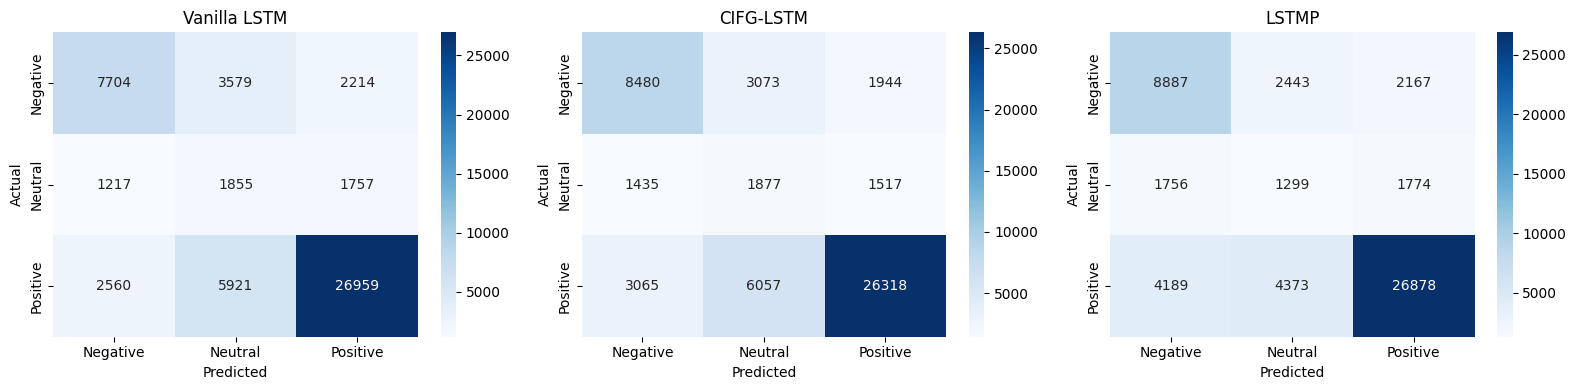

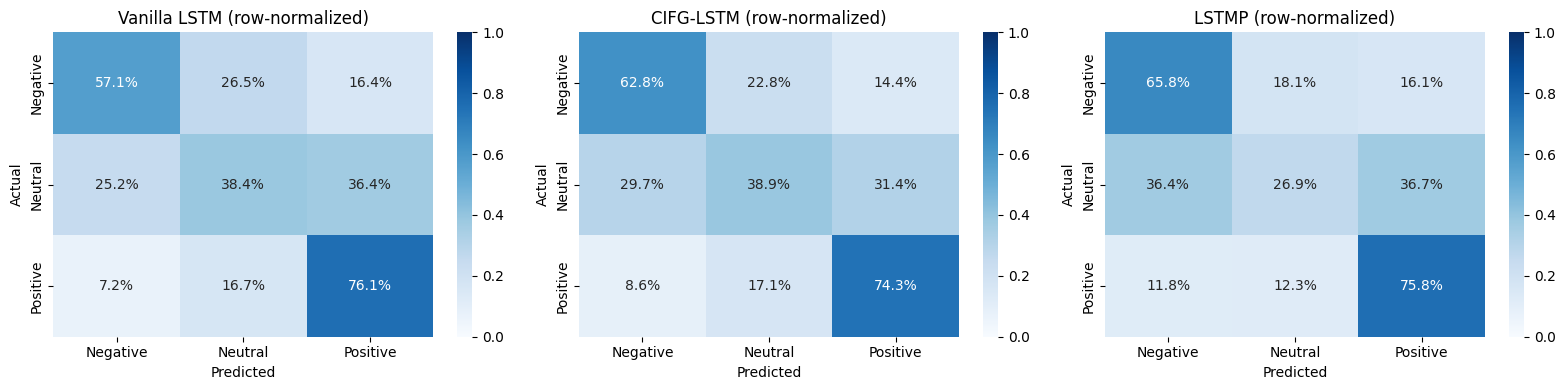

In [33]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

os.makedirs("results", exist_ok=True)

# 1. Confusion matrices: raw counts
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (model_name, (y_true, y_pred)) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=LABEL_NAMES,
        yticklabels=LABEL_NAMES,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("results/test_confusion_matrices_counts.png", dpi=200)
plt.show()


# 2. Confusion matrices: normalized by actual class
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (model_name, (y_true, y_pred)) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        normalize="true"
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=".1%",
        cmap="Blues",
        xticklabels=LABEL_NAMES,
        yticklabels=LABEL_NAMES,
        vmin=0,
        vmax=1,
        ax=ax
    )

    ax.set_title(model_name + " (row-normalized)")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("results/test_confusion_matrices_normalized.png", dpi=200)
plt.show()

## 15. Learning curves for selected runs
The selected model checkpoints are used for test evaluation. Histories are saved for every hyperparameter run.

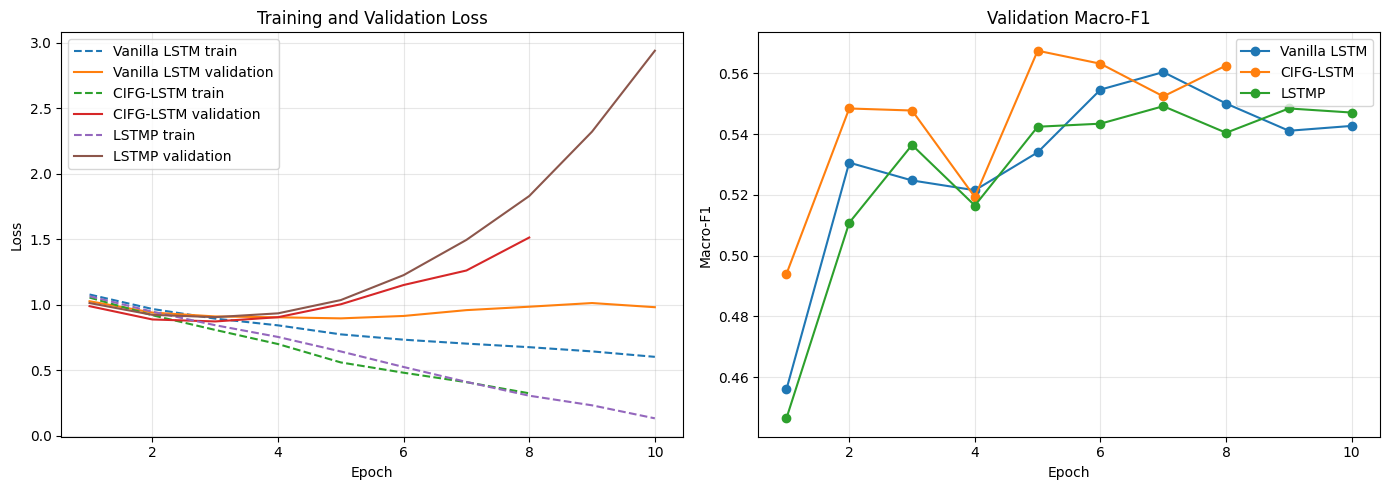

In [34]:
# Plot training/validation curves for the best config of each architecture

import os
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name in MODEL_CONFIGS:
    hp = best_settings[model_name]
    run_name = f"{model_name}__{hp['config']}"
    hist = experiment_histories[run_name]

    # Training and validation loss
    axes[0].plot(
        hist["epoch"],
        hist["train_loss"],
        linestyle="--",
        label=f"{model_name} train"
    )

    axes[0].plot(
        hist["epoch"],
        hist["val_loss"],
        label=f"{model_name} validation"
    )

    # Validation Macro-F1
    axes[1].plot(
        hist["epoch"],
        hist["val_macro_f1"],
        marker="o",
        label=model_name
    )

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/selected_models_learning_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

## 16. Save a reproducibility summary

In [35]:
import os
import json

os.makedirs("results", exist_ok=True)

summary = {
    "seed": SEED,
    "device": str(DEVICE),
    "vocabulary_size": len(vocab),
    "max_sequence_length": MAX_LEN,
    "embedding_dim": EMBED_DIM,

    # Actual dataset sizes used in the experiment
    "split_sizes": {
        "train": len(train_small),
        "validation": len(val_small),
        "test": len(test_full)
    },

    "dataset_reduction": {
        "training_percentage": 60,
        "validation_percentage": 60,
        "test_percentage": 100
    },

    "selected_hyperparameters": best_settings,
    "final_test_results": final_results_df.to_dict("records"),
    "hyperparameter_experiments": hp_results_df.to_dict("records")
}

with open("results/experiment_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("Summary saved to results/experiment_summary.json")

Summary saved to results/experiment_summary.json


## 17. Download result files

In [36]:
import shutil, os
from IPython.display import FileLink, display

assert os.path.isdir("results"), "No results directory was created"
zip_path = os.path.abspath(shutil.make_archive("results", "zip", root_dir=".", base_dir="results"))
print("Results archive:", zip_path)
print("Archive size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))
display(FileLink(zip_path))

Results archive: /content/results.zip
Archive size (MB): 42.81


/content/results.zip